This notebook reproduces results from Section VI: Platonic Solids of the paper
"Phase locking and multistability in the topological Kuramoto model on cell complexes".

It prints relevant boundary matrices and kernel matrices and creates Figures 5 and 6.

In [1]:
import numpy as np

from core.complexes import compute_boundary_matrices, get_C_from_B, get_K_from_B

from core.dynamics import (
    find_all_plus_omega_zero_solutions,
    get_psi_minus_sp,
    get_psi_plus_sp,
    find_what_works_nd,
    check_stable_jacobians
)

from core.platonic_solids import (
    get_platonic_solids,
    make_figure_6,
    sweep_omega0_all_plus,
    make_figure_7,
    make_featured_image_all_9_cube_states,
    lift_equilibrium_from_windings
)


Import and print Platonic Solids data

In [2]:
solids = get_platonic_solids()
for name, (vertices, edges, faces, volumes) in solids.items():
    print(f"{name}:")
    print(f"  vertices count: {len(vertices)}")
    print(f"  edges count: {len(edges)}")
    print(f"  faces count: {len(faces)}")
    print(f"  volumes count: {len(volumes)}")
    print()


tetrahedron:
  vertices count: 4
  edges count: 6
  faces count: 4
  volumes count: 1

cube:
  vertices count: 8
  edges count: 12
  faces count: 6
  volumes count: 1

octahedron:
  vertices count: 6
  edges count: 12
  faces count: 8
  volumes count: 1

dodecahedron:
  vertices count: 20
  edges count: 30
  faces count: 12
  volumes count: 1

icosahedron:
  vertices count: 12
  edges count: 30
  faces count: 20
  volumes count: 1



# Boundary matrices for all platonic solids

In [3]:
for name, (S0, S1, S2, S3) in solids.items():
    print(f"\n{'='*60}")
    print(f"{name.upper()} — boundary matrices")
    print(f"{'='*60}")

    S = [S0, S1, S2, S3]  # 0-cells, 1-cells, 2-cells, 3-cell
    B = compute_boundary_matrices(S)

    for k, Bk in enumerate(B, start=1):
        print(f"\nB{k} (maps from S_{k} to S_{k-1}): shape {Bk.shape}")
        print(Bk)


TETRAHEDRON — boundary matrices

B1 (maps from S_1 to S_0): shape (4, 6)
[[-1 -1 -1  0  0  0]
 [ 1  0  0 -1 -1  0]
 [ 0  1  0  1  0 -1]
 [ 0  0  1  0  1  1]]

B2 (maps from S_2 to S_1): shape (6, 4)
[[ 1 -1  0  0]
 [-1  0  0  1]
 [ 0  1  0 -1]
 [ 1  0 -1  0]
 [ 0 -1  1  0]
 [ 0  0 -1  1]]

B3 (maps from S_3 to S_2): shape (4, 1)
[[1]
 [1]
 [1]
 [1]]

CUBE — boundary matrices

B1 (maps from S_1 to S_0): shape (8, 12)
[[-1 -1 -1  0  0  0  0  0  0  0  0  0]
 [ 1  0  0 -1 -1  0  0  0  0  0  0  0]
 [ 0  0  0  1  0 -1 -1  0  0  0  0  0]
 [ 0  1  0  0  0  1  0 -1  0  0  0  0]
 [ 0  0  1  0  0  0  0  0 -1 -1  0  0]
 [ 0  0  0  0  1  0  0  0  1  0 -1  0]
 [ 0  0  0  0  0  0  1  0  0  0  1 -1]
 [ 0  0  0  0  0  0  0  1  0  1  0  1]]

B2 (maps from S_2 to S_1): shape (12, 6)
[[ 1  0 -1  0  0  0]
 [-1  0  0  0  1  0]
 [ 0  0  1  0 -1  0]
 [ 1  0  0  0  0 -1]
 [ 0  0 -1  0  0  1]
 [ 1  0  0 -1  0  0]
 [ 0  0  0  1  0 -1]
 [ 0  0  0 -1  1  0]
 [ 0 -1  1  0  0  0]
 [ 0  1  0  0 -1  0]
 [ 0 -1  0  0 

We will focus on the n=1 case. We start by printing $C_1$ and $C_2$ for n=1.

In [4]:
for name, (S0, S1, S2, S3) in solids.items():
    print(f"\n{'='*60}")
    print(f"{name.upper()} — C1 and C2 matrices (n=1)")
    print(f"{'='*60}")

    S = [S0, S1, S2, S3]
    B1, B2, B3 = compute_boundary_matrices(S)
    C1, C2 = get_C_from_B(B1, B2)

    print(f"\nC1 shape {C1.shape}  (satisfies  B1.T @ C1.T = 0; columns of C1^T span ker(B1^T)):")
    print(C1)
    print(f"\nC2 shape {C2.shape}  (satisfies  B2 @ C2   = 0; columns of C2   span ker(B2)):")
    print(C2)


TETRAHEDRON — C1 and C2 matrices (n=1)

C1 shape (1, 4)  (satisfies  B1.T @ C1.T = 0; columns of C1^T span ker(B1^T)):
[[1. 1. 1. 1.]]

C2 shape (4, 1)  (satisfies  B2 @ C2   = 0; columns of C2   span ker(B2)):
[[1.]
 [1.]
 [1.]
 [1.]]

CUBE — C1 and C2 matrices (n=1)

C1 shape (1, 8)  (satisfies  B1.T @ C1.T = 0; columns of C1^T span ker(B1^T)):
[[1. 1. 1. 1. 1. 1. 1. 1.]]

C2 shape (6, 1)  (satisfies  B2 @ C2   = 0; columns of C2   span ker(B2)):
[[1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]]

OCTAHEDRON — C1 and C2 matrices (n=1)

C1 shape (1, 6)  (satisfies  B1.T @ C1.T = 0; columns of C1^T span ker(B1^T)):
[[1. 1. 1. 1. 1. 1.]]

C2 shape (8, 1)  (satisfies  B2 @ C2   = 0; columns of C2   span ker(B2)):
[[1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]]

DODECAHEDRON — C1 and C2 matrices (n=1)

C1 shape (1, 20)  (satisfies  B1.T @ C1.T = 0; columns of C1^T span ker(B1^T)):
[[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]

C2 shape (12, 1)  (satisfies  B2 @ C2   = 0; columns of 

Let us now find and classify all roots for n = 1. 

In [5]:
roots_ps_n1 = []
n = 1
solids = get_platonic_solids()
for key in solids:
    print(f"---{key}---")
    S = solids[key]
    sols = find_all_plus_omega_zero_solutions(S, n, False, tol = 1e-7)
    roots_ps_n1.append(sols)

---tetrahedron---
n = 1,
C_n = [[1. 1. 1. 1.]],
C_np1 = [[1.]
 [1.]
 [1.]
 [1.]]
total of 1 different z_n_vecs considered, and 1 different z_np1_vecs.
Phase-locked solutions:
(z_plus, z_minus) = ((0,), (0,))
zeta_plus = [0.], zeta_minus = [0.]
Solution z+ = (0,), z- = (0,): is stable.
Solution z+ = (0,), z- = (0,): all cos(theta) > 0.
Root 1: z+ = (0,), z- = (0,), zeta_plus = [0.], zeta_minus = [0.], Stable: True, Positive: True
Cos(theta)_minus: [1. 1. 1. 1.] 
 Eig J1:[-4.00000000e+00 -4.00000000e+00 -4.00000000e+00 -3.33814172e-16
  0.00000000e+00  7.47264880e-19]
 Cos(theta)_plus: [1. 1. 1. 1.]
 Eig J2:[-4.00000000e+00 -4.00000000e+00 -4.00000000e+00 -2.63677968e-16
 -2.22044605e-16  0.00000000e+00]

---cube---
n = 1,
C_n = [[1. 1. 1. 1. 1. 1. 1. 1.]],
C_np1 = [[1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]]
total of 3 different z_n_vecs considered, and 3 different z_np1_vecs.
Phase-locked solutions:
(z_plus, z_minus) = ((-1,), (-1,))
zeta_plus = [-0.8660254], zeta_minus = [-0.70710678]
(z_plus

# Figure 6

In (a), we plot the number of stable solutions depending on the Platonic Solid.

In (b), we plot stable phase-locked solutions for all Platonic solids (black dots).
We use same colors and different line styles denote dual Platonic solids to emphasize symmetry. Other than the tetrahedron, all objects exhibit structural multistability cascades where multistability arises due to interactions from both below and above.
In (c), we present these solutions in the $(\zeta^{[+]}, \zeta^{[-]})$ plane for the four objects that exhibit multistability.

total of 1 different z_n_vecs considered, and 1 different z_np1_vecs.
Phase-locked solutions:
(z_plus, z_minus) = ((0,), (0,))
zeta_plus = [0.], zeta_minus = [0.]
Solution z+ = (0,), z- = (0,): is stable.
total of 3 different z_n_vecs considered, and 3 different z_np1_vecs.
Phase-locked solutions:
(z_plus, z_minus) = ((-1,), (-1,))
zeta_plus = [-0.8660254], zeta_minus = [-0.70710678]
(z_plus, z_minus) = ((-1,), (0,))
zeta_plus = [-0.8660254], zeta_minus = [0.]
(z_plus, z_minus) = ((-1,), (1,))
zeta_plus = [-0.8660254], zeta_minus = [0.70710678]
(z_plus, z_minus) = ((0,), (-1,))
zeta_plus = [0.], zeta_minus = [-0.70710678]
(z_plus, z_minus) = ((0,), (0,))
zeta_plus = [0.], zeta_minus = [0.]
(z_plus, z_minus) = ((0,), (1,))
zeta_plus = [0.], zeta_minus = [0.70710678]
(z_plus, z_minus) = ((1,), (-1,))
zeta_plus = [0.8660254], zeta_minus = [-0.70710678]
(z_plus, z_minus) = ((1,), (0,))
zeta_plus = [0.8660254], zeta_minus = [0.]
(z_plus, z_minus) = ((1,), (1,))
zeta_plus = [0.8660254], zeta

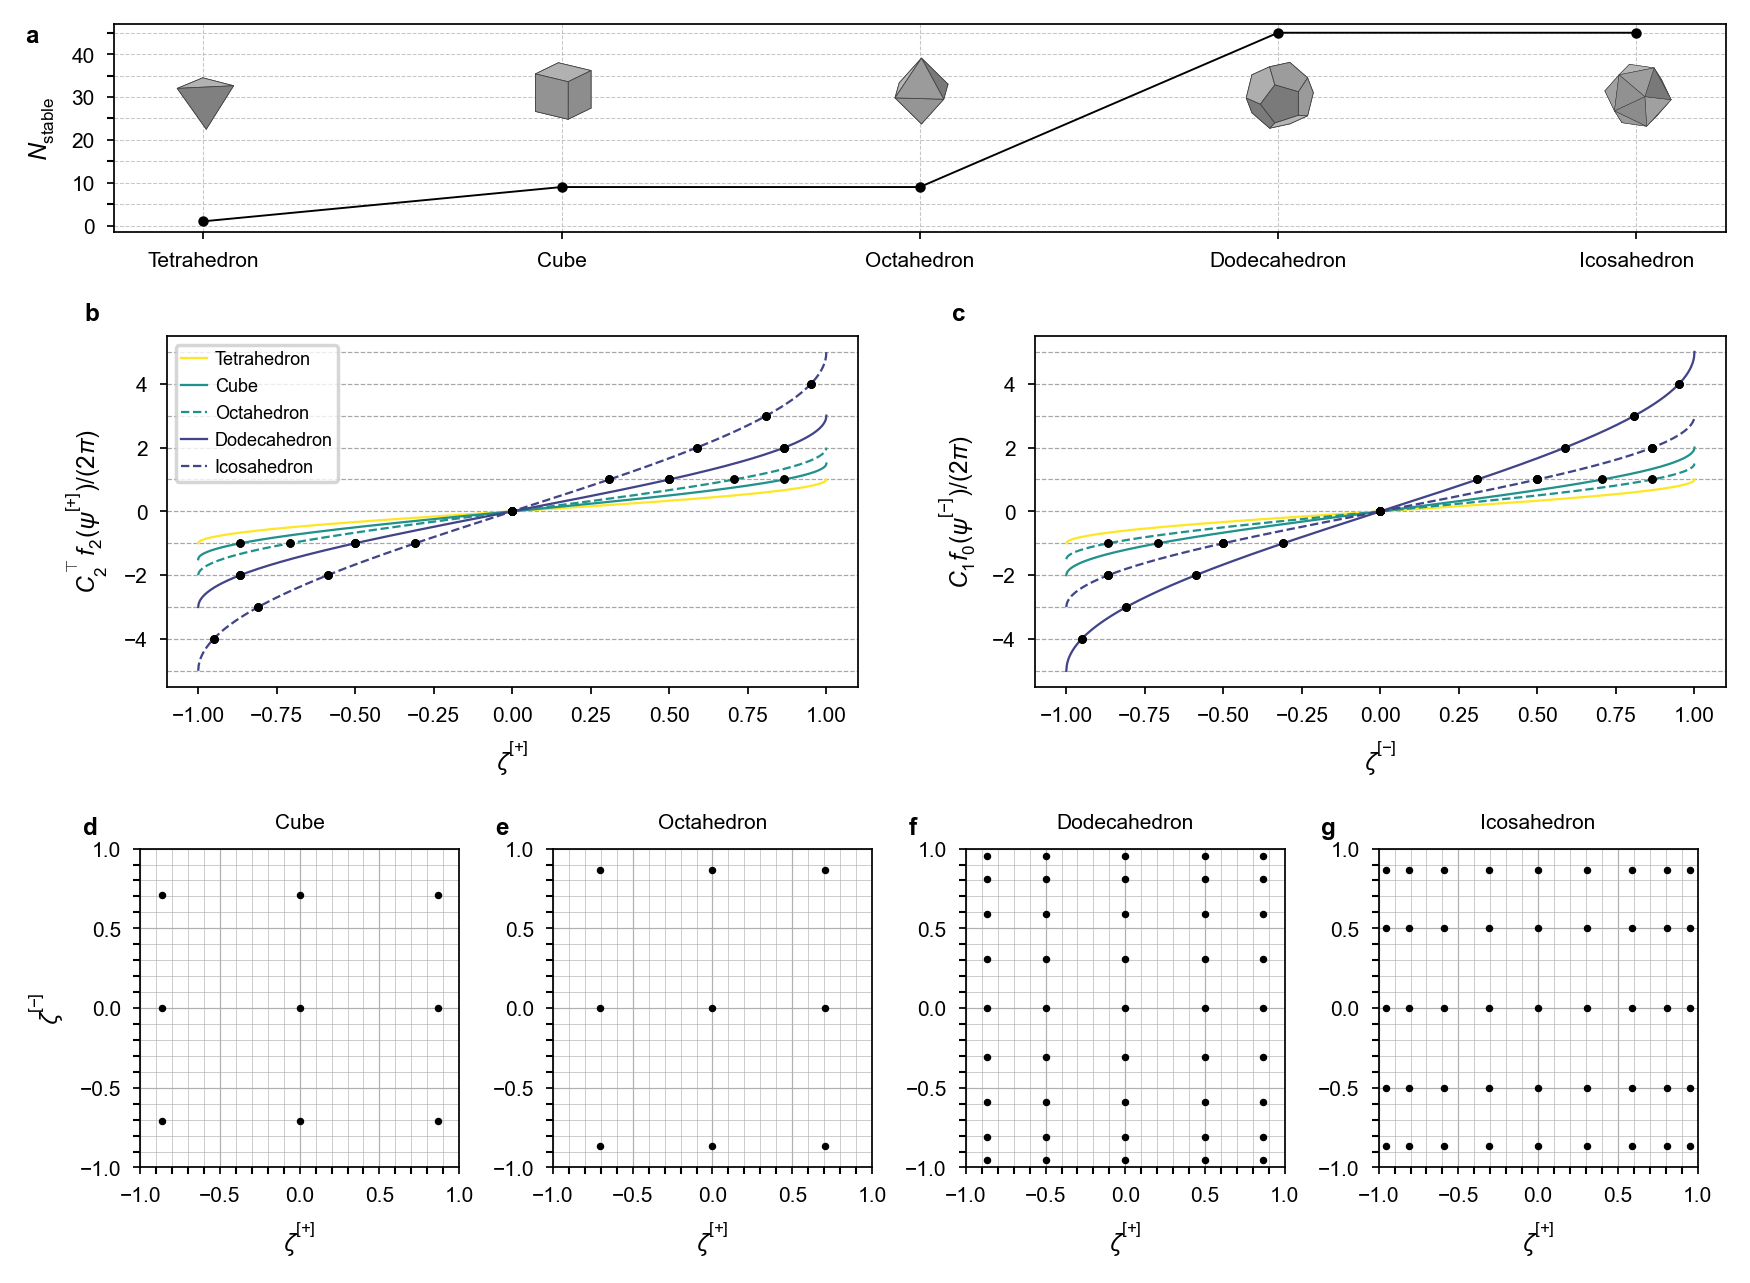

In [ ]:
ps_data_list = []

for name, (S0, S1, S2, S3) in get_platonic_solids().items():
    B = compute_boundary_matrices([S0, S1, S2, S3])
    B1, B2 = B[:2]
    C1, C2 = get_C_from_B(B1, B2)
    K1, K2 = get_K_from_B(B1, B2)

    omega = np.zeros(B1.shape[1])
    psi_minus_sp = get_psi_minus_sp(B1, K1, omega)
    psi_plus_sp  = get_psi_plus_sp(B2, K2, omega)

    # Get partitions: all-plus 
    S0_plus, S0_minus = list(range(len(S0))), []
    S2_plus, S2_minus = list(range(len(S2))), []

    roots = find_what_works_nd(S0_plus, S0_minus, S2_plus, S2_minus, B1, B2, K1, K2, C1, C2, tol=1e-7, omega=omega)
    stable_indices, *_ = check_stable_jacobians(roots, omega, B1, B2, K1, K2, C1, C2, S0_plus, S0_minus, S2_plus, S2_minus)

    ps_data_list.append({
        "psi_plus_sp": psi_plus_sp,
        "psi_minus_sp": psi_minus_sp,
        "K1": K1, "K2": K2, "C1": C1, "C2": C2,
        "S0_plus": S0_plus, "S0_minus": S0_minus,
        "S2_plus": S2_plus, "S2_minus": S2_minus,
        "roots": roots,
        "stable_indices": stable_indices,
        "label": name.capitalize(),
    })

make_figure_6(roots_ps_n1, ps_data_list, save_path="Fig6final.pdf")

# Figure 7

Finally, let us consider the effect of inhomogeinity in the intrinsic frequencies $\vec \omega$.
We demonstrate our results in the cube - the simplest Platonic Solid that exhibits multistability - and set $\vec \omega = (0, 0, 0, 0, 0, 0, 0, 0, +\omega_0, 0, 0, \omega_0 )$.

$\omega_0$ = 0.000
total of 3 different z_n_vecs considered, and 3 different z_np1_vecs.
Phase-locked solutions:
(z_plus, z_minus) = ((-1,), (-1,))
zeta_plus = [-0.8660254], zeta_minus = [-0.70710678]
(z_plus, z_minus) = ((-1,), (0,))
zeta_plus = [-0.8660254], zeta_minus = [0.]
(z_plus, z_minus) = ((-1,), (1,))
zeta_plus = [-0.8660254], zeta_minus = [0.70710678]
(z_plus, z_minus) = ((0,), (-1,))
zeta_plus = [0.], zeta_minus = [-0.70710678]
(z_plus, z_minus) = ((0,), (0,))
zeta_plus = [0.], zeta_minus = [0.]
(z_plus, z_minus) = ((0,), (1,))
zeta_plus = [0.], zeta_minus = [0.70710678]
(z_plus, z_minus) = ((1,), (-1,))
zeta_plus = [0.8660254], zeta_minus = [-0.70710678]
(z_plus, z_minus) = ((1,), (0,))
zeta_plus = [0.8660254], zeta_minus = [0.]
(z_plus, z_minus) = ((1,), (1,))
zeta_plus = [0.8660254], zeta_minus = [0.70710678]
Solution z+ = (-1,), z- = (-1,): is stable.
Solution z+ = (-1,), z- = (0,): is stable.
Solution z+ = (-1,), z- = (1,): is stable.
Solution z+ = (0,), z- = (-1,): is

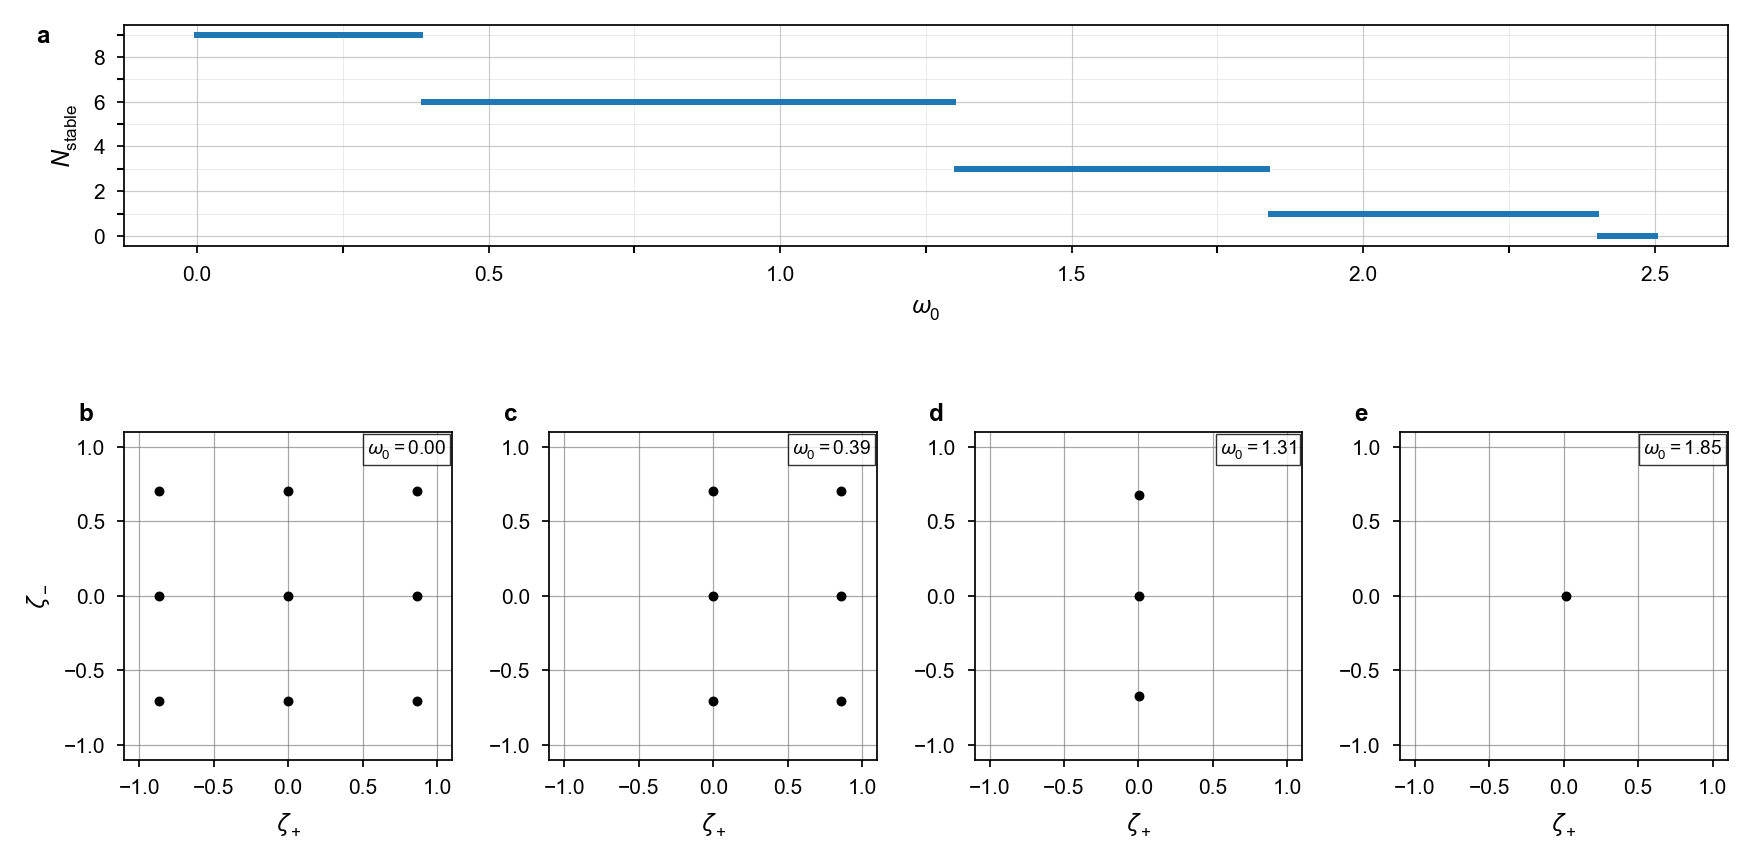

In [ ]:
selected_omegas = [0.0, 0.39, 1.31, 1.85]

omega0_vals = np.linspace(0.0, 2.5, 400)


B1c, B2c = compute_boundary_matrices(solids['cube'][:3])
C1c, C2c = get_C_from_B(B1c, B2c)
K1c, K2c = get_K_from_B(B1c, B2c)

stable_counts, all_results, all_omegas = sweep_omega0_all_plus(B1c, B2c, K1c, K2c, C1c, C2c, omega0_vals=omega0_vals, S0_plus=list(range(8)), S2_plus=list(range(6)))

make_figure_7(omega0_vals, stable_counts, all_results, all_omegas, selected_omegas, save_path="Fig7final.pdf")

# Featured image

This image shows the nine stable phase-locked states of the topological Kuramoto dynamics on a cubical complex. Each cube represents one stable equilibrium indexed by the winding numbers $(z^{[-]}, z^{[+]}) \in \{-1,0,1\}^2$. The colours on the cube edges encode the final edge phases $\theta_{[j,k]}$ using a cyclic phase colormap. Although the projected winding angles $\theta^{[-]}$ and $\theta^{[+]}$ are uniform for each state, the lifted edge phases are generally nonuniform, producing distinct colour patterns across the cube edges.

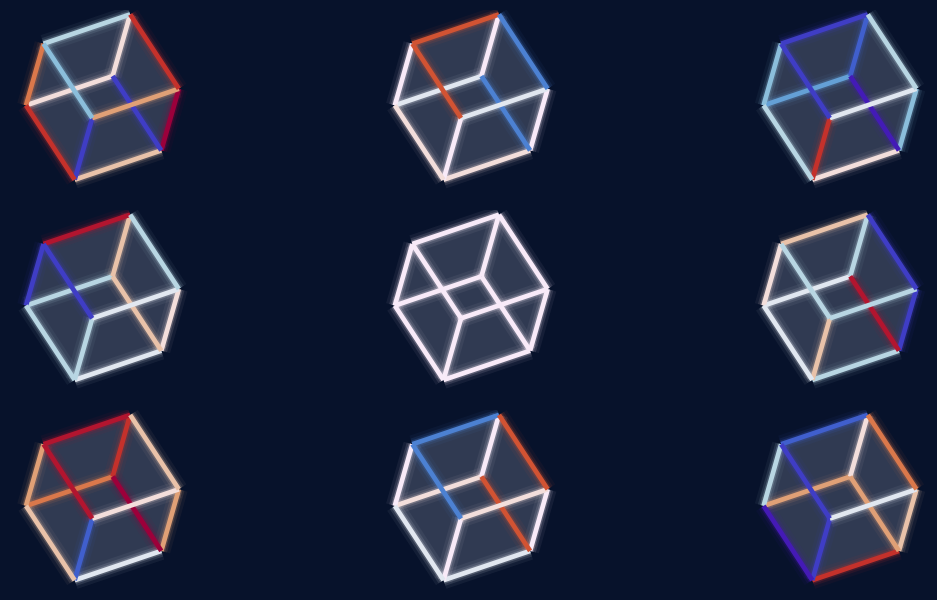

In [2]:
B1_draw = np.array([
    [-1,  0,  0, +1,  0,  0,  0,  0, -1,  0,  0,  0],
    [+1, -1,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0],
    [ 0, +1, -1,  0,  0,  0,  0,  0,  0,  0, -1,  0],
    [ 0,  0, +1, -1,  0,  0,  0,  0,  0,  0,  0, -1],
    [ 0,  0,  0,  0, -1,  0,  0, +1, +1,  0,  0,  0],
    [ 0,  0,  0,  0, +1, -1,  0,  0,  0, +1,  0,  0],
    [ 0,  0,  0,  0,  0, +1, -1,  0,  0,  0, +1,  0],
    [ 0,  0,  0,  0,  0,  0, +1, -1,  0,  0,  0, +1],
], dtype=int)

B2_drawT = np.array([
    [+1, +1, +1, +1,  0,  0,  0,  0,  0,  0,  0,  0],
    [ 0,  0,  0,  0, +1, +1, +1, +1,  0,  0,  0,  0],
    [-1,  0,  0,  0, +1,  0,  0,  0, +1, -1,  0,  0],
    [ 0,  0, +1,  0,  0,  0, -1,  0,  0,  0, -1, +1],
    [ 0,  0,  0, +1,  0,  0,  0, -1, +1,  0,  0, -1],
    [ 0, -1,  0,  0,  0, +1,  0,  0,  0, +1, -1,  0],
], dtype=int)

B2_drawT = B2_drawT.T

make_featured_image_all_9_cube_states(B1_draw, B2_drawT, save_path="featured_image_suggestion.png")